# E-Commerce Customer Churn Analysis (ML Model) / Analiza Rezygnacji Klientów w Serwisie E-Commerce (ML Model)

## 1. Project goal / Cel projektu

### ENG

> **About the project**
>
> Following the insights from the Exploratory Data Analysis (EDA), this second part of the project focuses on **building, tuning, and evaluating Machine Learning models to predict customer churn in an e-commerce platform**. The primary goal is to accurately identify customers at risk of churn and understand the key drivers behind their decisions.
>
> **Scope of the notebook**
>
> * Building **processing pipelines** (`Pipeline`), where integrating scaling (`StandardScaler`), categorical encoding (`ColumnTransformer`), and class balancing (`SMOTE`) into unified workflows eliminates the risk of data leakage.
> * **Model training and hyperparameter tuning**, including the evaluation of multiple algorithms (Logistic Regression, Random Forest, XGBoost) using cross-validation (`StratifiedKFold`) and `GridSearchCV` optimization.
> * Translating model outputs into business insights via Odds Ratios in Logistic Regression and SHAP explainability methods.
> * Applying the final model to the holdout test set (`test_data`) to generate actionable business recommendations.
>
> **Production standards & next steps**
>
> The entire data processing workflow and SMOTE oversampling take place strictly within the cross-validation loops, ensuring full alignment with production standards. The final deliverable of this notebook is an optimized classifier along with a ready-to-use list of new customers targeted for a retention campaign (`churn_risk_clients.csv`).

### PL

> **O projekcie**
>
> W nawiązaniu do wniosków z Eksploracyjnej Analizy Danych (EDA), druga część projektu skupia się na **budowie, dostrajaniu oraz ewaluacji modeli uczenia maszynowego do predykcji churnu w serwisie e-commerce**. Głównym celem jest precyzyjne wytypowanie klientów zagrożonych odejściem oraz zrozumienie kluczowych czynników wpływających na ich decyzje.
>
> **Zakres tego notatnika**
>
> * Integracja standaryzacji (`StandardScaler`), kodowania zmiennych kategorycznych (`ColumnTransformer`) oraz równoważenia klas (`SMOTE`) w **unikalne potoki przetwarzania (pipelines)** w celu eliminacji ryzyko przecieku danych.
> * **Trening modelu i tuning hiperparametrów**, w tym ewaluacja algorytmów (regresja logistyczna, Random Forest, XGBoost) przy użyciu walidacji krzyżowej (`StratifiedKFold`) oraz optymalizacji `GridSearchCV`.
> * Przełożenie wyników modelu na język biznesu poprzez ilorazy szans (*Odds Ratios*) dla regresji logistycznej oraz wyjaśnienia SHAP.
> * Zastosowanie ostatecznego modelu na wyizolowanym zbiorze testowym (`test_data`) w celu wygenerowania gotowych rekomendacji biznesowych.
>
> **Realia produkcyjne i dalsze kroki**
>
> Cały proces przetwarzania danych i przepróbkowania SMOTE odbywa się wyłącznie wewnątrz pętli walidacji krzyżowej, co zapewnia pełne zachowanie standardów produkcyjnych. Końcowym produktem notatnika jest zoptymalizowany klasyfikator oraz gotowa lista nowych klientów zakwalifikowanych do kampanii retencyjnej (`churn_risk_clients.csv`).

## 2. Libraries and data loading / Import bibliotek i danych

### 2.1. Libraries / Biblioteki

In [3]:
import pandas as pd
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, roc_auc_score
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.model_selection import GridSearchCV
import shap
import joblib

### 2.2. Data loading / Wczytywanie danych

In [6]:
#historical client base / baza historyczna
X_train = pd.read_csv('traindata_ecommerce_clean.csv')
y_train = pd.read_csv('ytrain_ecommerce_clean.csv')

#new client base / nowa baza
X_test = pd.read_csv('Xtest_ecommerce_clean.csv')
y_test = pd.read_csv('ytest_ecommerce_clean.csv')

print(f"Historical client base (X_train): {X_train.shape[0]} records, {X_train.shape[1]} variables")
print(f"New client base (X_test): {X_test.shape[0]} records")

Historical client base (X_train): 2712 records, 10 variables
New client base (X_test): 768 records


In [7]:
X_train = X_train.reset_index(drop=True)
y_train = y_train.reset_index(drop=True)

In [8]:
y_train = y_train.squeeze()
y_test = y_test.squeeze()

#one-hot encoding / kodowanie zmiennych
X_train = pd.get_dummies(X_train, drop_first=True)
X_test = pd.get_dummies(X_test, drop_first=True)

## 3. Model training / Trenowanie modelu

### ENG

> Initial comparison of three diverse classification algorithms: **logistic regression**, **random forest**, and **XGBoost**.

> **Stratified 5-fold cross-validation (`StratifiedKFold`)**
> 
> The training set (`X_train`) is divided into 5 equal parts while preserving the proportion of the minority class (churning customers). This prevents instability in metric evaluations across individual loops.

> **Integration in processing pipelines (`Pipeline`)**
> 
> To completely eliminate the risk of **data leakage**, all transformation steps—including numerical feature standardization (`StandardScaler`) and generating synthetic samples via `SMOTE`—are performed **exclusively inside the cross-validation loop** on the training data of a given fold.

> **Evaluation**
> 
> Classification quality is estimated based on a set of key metrics for imbalanced problems: **F1-Score** (the primary metric balancing precision and recall), **ROC-AUC**, **Recall** (churn detection sensitivity), and **Precision**.

### PL

> Wtępne porównanie trzech zróżnicowanych algorytmów klasyfikacji: **regresji logistycznej**, **lasu losowego (random forest)** oraz **XGBoost**.

>**Stratyfikowana 5-krotna walidacja krzyżowa (`StratifiedKFold`)**
> 
>Zbiór treningowy (`X_train`) zostaje podzielony na 5 równych części z zachowaniem proporcji klasy mniejszościowej (odchodzących klientów). Zapobiega to niestabilności ocen metryk w poszczególnych pętlach.

>**Integracja w potokach przetwarzania (`Pipeline`)**
>
> Aby całkowicie wyeliminować ryzyko **przecieku danych (*data leakage*)**, wszystkie kroki transformacji, w tym standaryzacja cech numerycznych (`StandardScaler`) oraz generowanie sztucznych próbek `SMOTE` są wykonywane **wyłącznie wewnątrz pętli walidacji krzyżowej** na danych treningowych danego folda.

> **Ocena**
> 
>Jakość klasyfikacji szacujemy na podstawie zestawu metryk kluczowych w problemach niezrównoważonych: **F1-Score** (główna metryka zrównoważenia precyzji i czułości), **ROC-AUC**, **Recall** (czułość wykrywania churnu) oraz **Precision**.

### 3.1. Cross-validation / Walidacja krzyżowa

In [9]:
#defining StratifiedKFold / definiowanie 5krotnej walidacji krzyżowej z zachowaniem proporcji klas
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

#defining pipelines / definiowanie potoków przetwarzania
pipelines = {
    'Logistic Regression': Pipeline([
        ('scaler', StandardScaler()),
        ('smote', SMOTE(random_state=42)),
        ('classifier', LogisticRegression(random_state=42, max_iter=1000))
    ]),
    'Random Forest': Pipeline([
        ('smote', SMOTE(random_state=42)),
        ('classifier', RandomForestClassifier(random_state=42))
    ]),
    'XGBoost': Pipeline([
        ('smote', SMOTE(random_state=42)),
        ('classifier', XGBClassifier(random_state=42, eval_metric='logloss'))
    ])
}

#comparison of model cross-validation results on X_train / porównanie wyników walidacji krzyżowej na X_train
cv_results = {}

for name, pipeline in pipelines.items():
    scores = cross_validate(
        pipeline, 
        X_train, 
        y_train, 
        cv=cv, 
        scoring=['roc_auc', 'f1', 'recall', 'precision'],
        n_jobs=-1
    )
    cv_results[name] = {
        'ROC-AUC': scores['test_roc_auc'].mean(),
        'F1-Score': scores['test_f1'].mean(),
        'Recall': scores['test_recall'].mean(),
        'Precision': scores['test_precision'].mean()
    }

df_cv_results = pd.DataFrame(cv_results).T
print("=== Cross-validation results on historical base of clients (X_train) ===")
display(df_cv_results.style.highlight_max(axis=0, color='lightgreen'))

=== Cross-validation results on historical base of clients (X_train) ===


,ROC-AUC,F1-Score,Recall,Precision
Logistic Regression,0.881913,0.564517,0.805312,0.435024
Random Forest,0.928244,0.696201,0.719433,0.674955
XGBoost,0.924030,0.693871,0.687870,0.700905


### ENG

> **Logistic Regression**
> * Achieves the highest **Recall ($80.53\%$)**, meaning it captures the largest number of churning customers.
> * However, it exhibits a very low **Precision ($43.50\%$)** and the lowest **F1-Score ($0.5645$)**. In practice, it generates a high volume of false alarms (False Positives) by classifying loyal customers as at-risk, which increases the costs of retention campaigns.

> **XGBoost**
> * Achieves the highest precision **Precision ($70.09\%$)**, making the most accurate hits, but this comes at the expense of a lower **Recall = $68.79\%$** (missing a larger number of actual churns).
> * Achieves a very high **ROC-AUC ($0.9240$)** and **F1-Score ($0.6939$)**.

> **Random Forest**
> * Dominates in the primary overall quality evaluation metric: **ROC-AUC ($0.9282$)** and **F1-Score ($0.6962$)**.
> * Maintains the most optimal balance between detecting churns (**Recall = $71.94\%$**) and avoiding false alarms (**Precision = $67.50\%$**).

> **Random Forest** is selected for the hyperparameter tuning phase using `GridSearchCV`.
> 
> * In the context of preventing customer churn, we aimed to minimize both the costs of failing to act on a churning customer (shortfalls in *Recall*) and the costs of unnecessary discounts sent to loyal customers (shortfalls in *Precision*). Random Forest provides the optimal trade-off (the highest **F1-Score**).
> * Achieving the highest **ROC-AUC ($0.9282$)** score demonstrates the model's excellent class separation capability regardless of the chosen threshold, providing an ideal foundation for subsequent tuning and decision threshold adjustment.

### PL

>**Regresja logistyczna**
> * Osiąga najwyższy wskaźnik **Recall ($80.53\%$)**, co oznacza, że wyłapuje najwięcej odchodzących klientów. 
>* Wykazuje jednak bardzo niską **Precision ($43.50\%$)** oraz najniższy **F1-Score ($0.5645$)**. W praktyce generuje bardzo dużo fałszywych alarmów (False Positives), klasyfikując stałych klientów jako zagrożonych odejściem, co podnosi koszty kampanii retencyjnych.

>**XGBoost**
>  * Osiąga najwyższą precyzję **Precision ($70.09\%$)**, tworząc najbardziej trafne trafienia, ale odbywa się to kosztem niższego wskaźnika **Recall = $68.79\%$** (przeoczenie większej liczby rzeczywistych odejść).
>  * Osiąga bardzo wysoki **ROC-AUC ($0.9240$)** oraz **F1-Score ($0.6939$)**.

>**Las losowy (Random Forest)**
>  * Dominacja w głównej metryce oceny jakości ogólnej: **ROC-AUC ($0.9282$)** oraz **F1-Score ($0.6962$)**.
>  * Utrzymuje najbardziej optymalny balans pomiędzy wykrywaniem odejść (**Recall = $71.94\%$**) a unikaniem fałszywych alarmów (**Precision = $67.50\%$**).
>

>Do etapu strojenia hiperparametrów za pomocą `GridSearchCV` zostaje wybrany **Random Forest**.
>
> * W kontekście przeciwdziałania rezygnacjom klientów zależało nam na zminimalizowaniu zarówno kosztów niepodjęcia działań wobec odchodzącego klienta (braki w *Recall*), jak i kosztów niepotrzebnych rabatów wysyłanych do stałych klientów (braki w *Precision*). Random Forest zapewnia optymalny kompromis (najwyższy **F1-Score**).
> * Osiągnięcie najwyższego wyniku **ROC-AUC ($0.9282$)** świadczy o doskonałej zdolności separacji klas przez model niezależnie od przyjętego progu odcięcia, co stanowi idealny fundament pod późniejszy tuning i dostrajanie progu decyzyjnego.

### 3.2. Random Forest / Las losowy

> **Random Forest** is a powerful machine learning algorithm based on ensemble learning, specifically the bagging (bootstrap aggregating) technique. It builds a "forest" consisting of many independent decision trees, each trained on a random subset of data and features. The final prediction is the result of a majority vote across all trees. This algorithm is characterized by excellent resistance to overfitting, handles non-linear relationships remarkably well, and—unlike linear models—does not require the standardization of numerical features.

> **Las losowy** to potężny algorytm uczenia maszynowego oparty na metodzie zespołowej (*ensemble learning*), a dokładniej na technice *baggingu* (bootstrap aggregating). Buduje on "las" złożony z wielu niezależnych drzew decyzyjnych, z których każde uczy się na losowym podzbiorze danych i cech. Ostateczna predykcja jest wynikiem głosowania większościowego wszystkich drzew. Algorytm ten charakteryzuje się świetną odpornością na przeuczenie (*overfitting*), doskonale radzi sobie z nieliniowymi zależnościami oraz, w przeciwieństwie do modeli liniowych, nie wymaga standaryzacji cech numerycznych.

In [10]:
chosen_pipeline = pipelines['Random Forest']

#generating predictions Out-Of-Fold for confusion matrix 
y_train_pred = cross_val_predict(chosen_pipeline, X_train, y_train, cv=cv, method='predict')
y_train_proba = cross_val_predict(chosen_pipeline, X_train, y_train, cv=cv, method='predict_proba')[:, 1]

=== Classification Raport (Out-of-Fold CV) ===
              precision    recall  f1-score   support

           0       0.94      0.93      0.94      2270
           1       0.67      0.72      0.70       442

    accuracy                           0.90      2712
   macro avg       0.81      0.83      0.82      2712
weighted avg       0.90      0.90      0.90      2712



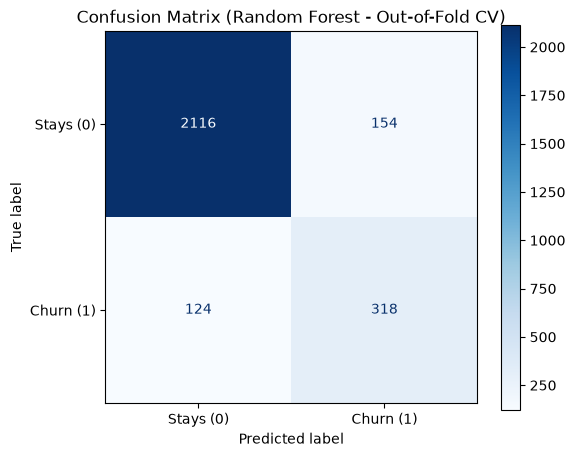

In [11]:
print("=== Classification Raport (Out-of-Fold CV) ===")
print(classification_report(y_train, y_train_pred))

#confusion matrix / macierz pomyłek
cm = confusion_matrix(y_train, y_train_pred)
fig, ax = plt.subplots(figsize=(6, 5))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Stays (0)', 'Churn (1)'])
disp.plot(cmap='Blues', ax=ax, values_format='d')
plt.title("Confusion Matrix (Random Forest - Out-of-Fold CV)")
plt.grid(False)
plt.show()

### ENG

> **Classification Results**
>
>**Churn Detection (Class 1)**
> * **Recall = $0.72$:** The model correctly identified **318 out of 442** actual churning customers.
> * **Precision = $0.67$:** Out of **472 customers** flagged by the model as at-risk of leaving, exactly **318 individuals** actually churned.
> * **F1-Score = $0.70$:** Reflects a stable and balanced model fit for the minority class.
>
>**Retained Customers (Class 0)**
> * The model achieves very high precision ($0.94$) and recall ($0.93$), correctly classifying **2116 out of 2270** customers staying with the store.

---

> **Confusion Matrix**
>
>**True Positives (318):**
> * 318 at-risk customers were detected early. This gives the marketing/retention department an opportunity to target them with a dedicated offer or discount and save their Customer Lifetime Value.
>
>**False Negatives (124):**
> * The model missed 124 customers who left without any preventative action taken by the company. This represents a direct risk of revenue loss.
>
>**False Positives (154):**
> * 154 loyal customers were incorrectly flagged as churning. The company incurs a low alternative cost here (e.g., sending an unnecessary discount coupon to a customer who would have stayed anyway).

---

> **Conclusions**
>
>**Evaluation**
> * An overall **Accuracy = $0.90$** alongside an F1-Score for Churn at **$0.70$** confirms that the Random Forest model handles class imbalance well without falling into severe overfitting.
>
>**Next Steps**
> * The obtained confusion matrix provides a solid benchmark for further hyperparameter tuning (`GridSearchCV`) or potential decision threshold adjustment (*Threshold Tuning*).

### PL

> **Wyniki klasyfikacji**
>
>**Wykrywanie churnu (klasa 1)**
>  * **Recall (Czułość) = $0.72$:** Model poprawnie zidentyfikował **318 z 442** faktycznie odchodzących klientów.
>  * **Precision (Precyzja) = $0.67$:** Spośród **472 klientów** wytypowanych przez model jako zagrożeni rezygnacją, dokładnie **318 osób** rzeczywiście odeszło.
>  * **F1-Score = $0.70$:** Odzwierciedla stabilne i zbalansowane dopasowanie modelu dla klasy mniejszościowej.
>
>**Klienci pozostający w serwisie (klasa 0)**
>  * Model osiąga bardzo wysoką precyzję ($0.94$) oraz czułość ($0.93$), prawidłowo klasyfikując **2116 z 2270** klientów pozostających w sklepie.

---

> **Macierz pomyłek**
>
>**Prawdziwie pozytywne (True Positives = 318):**
>   * 318 zagrożonych klientów zostało wcześnie wykrytych. Daje to działowi marketingu/retencji możliwość skierowania do nich dedykowanej oferty lub rabatu i uratowania ich wartości (*Customer Lifetime Value*).
>
> **Fałszywie negatywne (False Negatives = 124):**
>   * Model przeoczył 124 klientów, którzy odeszli bez podjęcia jakichkolwiek działań zapobiegawczych ze strony firmy. Jest to bezpośrednie ryzyko utraty przychodów.
>
>**Fałszywie pozytywne (False Positives = 154):**
>   * 154 lojalnych klientów zostało błędnie oznaczonych jako odchodzący. Firma ponosi tu niski koszt alternatywny (np. wysłanie niepotrzebnego kuponu zniżkowego do klienta, który i tak by został).

---

> **Wnioski**
>
>**Ocena**
> 
> * Wynik ogólnej dokładności **Accuracy = $0.90$** przy F1-Score dla Churnu na poziomie **$0.70$** potwierdza, że model Random Forest dobrze radzi sobie z nierównowagą klas bez popadania w skrajne przeuczenie.
> 
>**Kolejne kroki**
> 
> * Uzyskana macierz pomyłek stanowi solidny punkt odniesienia do dalszego tuningu hiperparametrów (`GridSearchCV`) lub ewentualnego dostrojenia progu decyzyjnego (*Threshold Tuning*).

## 4. Hyperparameter tuning / Optymalizacja hiperparametrów

> Following the preliminary verification of the baseline Random Forest model, we move on to the **hyperparameter tuning** phase using the `GridSearchCV` method. 
>
>**Key elements of the process**
>* **Parameter grid (`param_grid`):** We search through a combination space of key model parameters, such as the number of trees in the forest (`n_estimators`), the maximum tree depth (`max_depth`), the minimum number of samples required to split a node (`min_samples_split`), the minimum number of samples in a leaf (`min_samples_leaf`), and the split criterion (`criterion`: `gini` / `entropy`).
> 
>* **Business metric optimization:** The search process is aimed at maximizing the **F1-Score** metric (`scoring='f1'`), ensuring that the optimized model maintains an optimal balance between precision and recall in detecting churn.
> 
>* **Full validation security:** As `GridSearchCV` is nested or operates within a 5-fold cross-validation (`cv=cv`), the entire search and evaluation procedure is performed securely, without any risk of data leakage.

>Po wstępnej weryfikacji modelu bazowego Random Forest przechodzimy do fazy **dostrajania hiperparametrów** za pomocą metody `GridSearchCV`. 
>
>**Kluczowe elementy procesu**
>* **Siatka parametrów (`param_grid`):** Przeszukujemy przestrzeń kombinacji kluczowych parametrów modelu, takich jak liczba drzew w lesie (`n_estimators`), maksymalna głębokość drzewa (`max_depth`), minimalna liczba próbek wymagana do podziału węzła (`min_samples_split`), minimalna liczba próbek w liściu (`min_samples_leaf`) oraz kryterium podziału (`criterion`: `gini` / `entropy`).
> 
>* **Optymalizacja pod miarę biznesową:** Proces przeszukiwania jest ukierunkowany na maksymalizację metryki **F1-Score** (`scoring='f1'`), co zapewnia, że zoptymalizowany model zachowa optymalny balans między precyzją a czułością w wykrywaniu churnu.
> 
>* **Pełne bezpieczeństwo walidacji:** Ponieważ `GridSearchCV` jest zagnieżdżony lub operuje w ramach 5-krotnej walidacji krzyżowej (`cv=cv`), cała procedura przeszukiwania i oceny odbywa się w sposób bezpieczny, bez ryzyka wycieku danych.

### 4.1. Szukanie najlepszych parametrów

In [12]:
#parameters for Random Forest / parametry dla Random Forest
param_grid = {
    'classifier__n_estimators': [100, 200, 300],
    'classifier__max_depth': [10, 15, 20, None],
    'classifier__min_samples_split': [2, 5, 10],
    'classifier__min_samples_leaf': [1, 2, 4],
    'classifier__criterion': ['gini', 'entropy']
}

#defining GridSearchCV z optymalizacją pod miarę F1-score 
grid_search = GridSearchCV(
    estimator=pipelines['Random Forest'],
    param_grid=param_grid,
    cv=cv,
    scoring='f1',       
    n_jobs=-1,
    verbose=1
)

#looking for best parameters / szukanie najlepszych parametrów
grid_search.fit(X_train, y_train)

print(f"Best parameters: {grid_search.best_params_}")
print(f"Best F1-Score: {grid_search.best_score_:.4f}")

Fitting 5 folds for each of 216 candidates, totalling 1080 fits
Best parameters: {'classifier__criterion': 'entropy', 'classifier__max_depth': None, 'classifier__min_samples_leaf': 1, 'classifier__min_samples_split': 2, 'classifier__n_estimators': 200}
Best F1-Score: 0.7067


### ENG

> **Identified best parameters**
>* **Split criterion (`criterion`):** `entropy` – entropy proved slightly better than standard Gini in building purer splits within the trees.
>* **Maximum tree depth (`max_depth`):** `None` – the trees are allowed to grow without artificial depth restriction, adapting to complex relationships in the data.
>* **Minimum samples in leaf (`min_samples_leaf`):** `1` and in node (`min_samples_split`): `2`.
>* **Number of trees in forest (`n_estimators`):** `200` - the forest consists of 200 decision trees, ensuring stability and high predictive power.

> **Evaluation of tuning effectiveness**
>* The achieved **best F1-Score is $0.7067$** (compared to the preliminary baseline model, which had $0.6962$).
>* Hyperparameter tuning brought a slight improvement in churn detection quality. The parameters were chosen optimally, maximizing the model's ability to generalize to new data without introducing excessive overfitting. The model is fully ready to move on to the interpretation and feature importance analysis phase.

### PL

>**Zidentyfikowane najlepsze parametry**
>* **Kryterium podziału (`criterion`):** `entropy` - entropia okazała się nieco lepsza od standardowego Giniego w budowaniu bardziej czystych podziałów w drzewach.
>* **Maksymalna głębokość drzewa (`max_depth`):** `None` - drzewa mogą rosnąć bez sztucznego ograniczenia głębokości, dopasowując się do złożonych relacji w danych.
>* **Minimalna liczba próbek w liściu (`min_samples_leaf`):** `1` oraz w węźle (`min_samples_split`): `2`.
>* **Liczba drzew w lesie (`n_estimators`):** `200` - las składa się z 200 drzew decyzyjnych, co zapewnia stabilność i wysoką moc predykcyjną.

>**Ocena skuteczności tuningu**
>* Uzyskany **najlepszy F1-Score wynosi $0.7067$** (w porównaniu do wstępnego modelu bazowego, który miał $0.6962$).
>* Dostrajanie hiperparametrów przyniosło delikatną poprawę jakości wykrywania churnu. Parametry zostały dobrane w sposób optymalny, maksymalizując zdolność modelu do generalizacji na nowych danych bez wprowadzania nadmiernego przeuczenia. Model jest w pełni gotowy do przejścia do fazy interpretacji i analizy ważności cech.

### 4.2. Wyniki po dostrajaniu hiperparametrów

=== CLASSIFICATION REPORT AFTER TUNING ===
              precision    recall  f1-score   support

           0       0.95      0.93      0.94      2270
           1       0.68      0.73      0.71       442

    accuracy                           0.90      2712
   macro avg       0.81      0.83      0.82      2712
weighted avg       0.90      0.90      0.90      2712



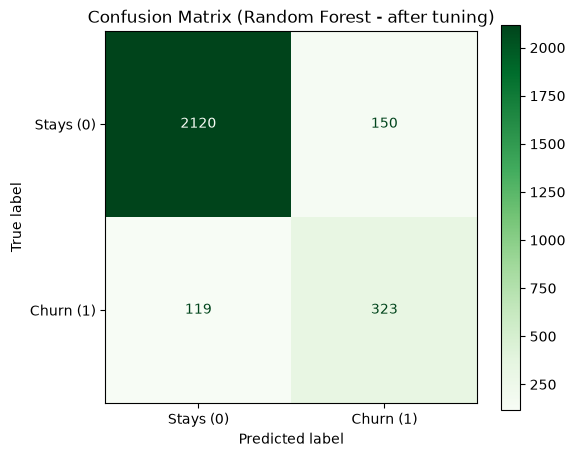

In [13]:
#best optimalized pipeline / najlepszy zoptymalizowany pipeline
best_pipeline = grid_search.best_estimator_

#Out-of-Fold prediction for optimalized model / predykcja Out-of-Fold dla najlepiej zoptymalizowanego modelu
y_train_pred_opt = cross_val_predict(best_pipeline, X_train, y_train, cv=cv, method='predict')

print("=== CLASSIFICATION REPORT AFTER TUNING ===")
print(classification_report(y_train, y_train_pred_opt))

#confusion matrix / macierz pomyłek
cm_opt = confusion_matrix(y_train, y_train_pred_opt)
fig, ax = plt.subplots(figsize=(6, 5))
disp = ConfusionMatrixDisplay(confusion_matrix=cm_opt, display_labels=['Stays (0)', 'Churn (1)'])
disp.plot(cmap='Greens', ax=ax, values_format='d')

plt.title("Confusion Matrix (Random Forest - after tuning)")
plt.grid(False)
plt.show()

### ENG

> **Results before and after hyperparameter tuning**
>
>**Churn detection (class 1)**
> * **Recall:** Increased from $0.72$ to **$0.73$**. The model correctly identified **323 out of 442** churning customers (5 more than before tuning).
> * **Precision:** Rose from $0.67$ to **$0.68$**. Out of 473 customers flagged as at-risk, exactly 323 actually churned.
> * **F1-Score:** Increased from $0.70$ to **$0.71$**, confirming an overall improvement in churn prevention quality.
>
>**Retained customers (class 0)**
> * Precision rose to **$0.95$**, and the F1-Score rose to **$0.94$**. The model generates slightly fewer false alarms, correctly classifying 2120 stable customers.

---

> **Confusion Matrix**
>
>**True Positives (323)**
>
>* The increased number of correctly detected risks enables more effective protection of company revenue.
>
>**False Negatives (119)**
>
>* The number of missed churns dropped from 124 to 119, which directly limits business losses.
>
>**False Positives (150)**
>
>* The decrease in false alarms from 154 to 150 optimizes the operational costs of retention campaigns (fewer unnecessary discounts for loyal customers).

---

> **Conclusions**
>
> The optimized **Random Forest** model achieved a stable overall accuracy of **Accuracy = $0.90$** while boosting key metrics for the minority class. The tuning process delivered measurable, albeit subtle, improvements in prediction quality. The model is fully verified and ready for interpretation to identify the main drivers of customer churn.

### PL

>**Wyniki przed i po tuningu hiperparametrów**
>
>**Wykrywanie churnu (klasa 1)**
>  * **Recall (Czułość):** Wzrosł z $0.72$ do **$0.73$**. Model poprawnie zidentyfikował **323 z 442** odchodzących klientów (o 5 więcej niż przed tuningiem).
>  * **Precision (Precyzja):** Wzrosła z $0.67$ do **$0.68$**. Spośród 473 klientów wskazanych jako zagrożeni, dokładnie 323 faktycznie zrezygnowało.
>  * **F1-Score:** Wzrósł z $0.70$ do **$0.71$**, co potwierdza ogólną poprawę jakości prewencji churnu.
>
>**Pozostający klienci (klasa 0)**
>  * Precision wzrosła do **$0.95$**, a F1-Score do **$0.94$**. Model popełnia nieco mniej fałszywych alarmów, poprawnie klasyfikując 2120 stabilnych klientów.

---

>**Macierz pomyłek**
>
>**Prawdziwie pozytywne (True Positives = 323)**
>
>* Zwiększona liczba poprawnie wykrytych zagrożeń pozwala na skuteczniejszą ochronę przychodów firmy.
>
>**Fałszywie negatywne (False Negatives = 119)**
>
>* Liczba przeoczonych odejść spadła ze 124 do 119, co bezpośrednio ogranicza straty biznesowe.
>
>**Fałszywie pozytywne (False Positives = 150)**
>
>* Spadek liczby fałszywych alarmów ze 154 do 150 optymalizuje koszty operacyjne kampanii retencyjnych (mniej niepotrzebnych rabatów dla stałych klientów).

---

>**Wnioski**
>
>Zoptymalizowany model **Random Forest** osiągnął stabilną dokładność ogólną **Accuracy = $0.90$** przy jednoczesnym podniesieniu kluczowych metryk dla klasy mniejszościowej. Proces tuningu przyniósł wymierne, chociaż subtelne ulepszenie jakości predykcji. Model jest w pełni zweryfikowany i gotowy do interpretacji w celu wskazania głównych czynników wpływających na odejście klientów.

## 5. Model explainability & Business interpretability / Interpretowalność biznesowa modelu

> High prediction accuracy is not enough in a business reality. To make effective decisions and implement targeted retention actions, we must thoroughly understand **why** the model makes specific decisions and **which customer features** most significantly increase the risk of leaving (churn).
>
> In this section, we move away from the so-called "black-box" toward full transparency using **explainable artificial intelligence (XAI)** tools, specifically the **SHAP (SHapley Additive exPlanations)** methodology. This will allow us to translate technical conclusions into concrete business recommendations for the marketing and customer service departments.

> Wysoki wynik predykcji nie wystarczy w realiach biznesowych. Aby podejmować skuteczne decyzje i wdrażać ukierunkowane akcje retencyjne, należy dokładnie rozumieć, **dlaczego** model podejmuje określone decyzje oraz **które cechy klientów** najbardziej nasilają ryzyko odejścia (churnu).
>
>W tej sekcji przechodzimy od tzw. „czarnej skrzynki” (*black-box*) do pełnej przejrzystości za pomocą narzędzi **wyjaśnialnej sztucznej inteligencji (XAI)**, a w szczególności metodologii **SHAP (SHapley Additive exPlanations)**. Pozwoli to przekształcić wnioski techniczne na konkretne rekomendacje biznesowe dla działu marketingu i obsługi klienta. 

### 5.1. Feature importance / Ważność cech

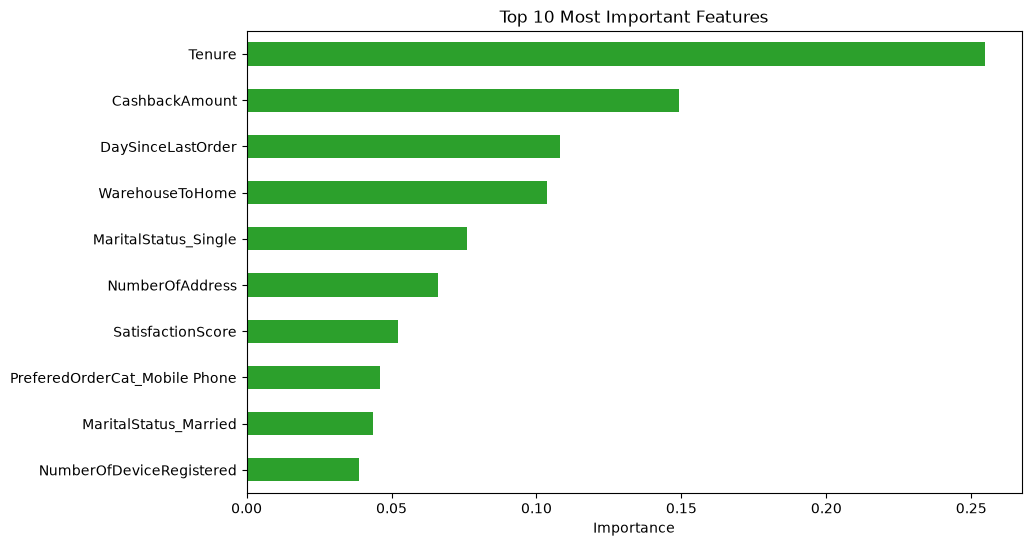

In [14]:
best_rf = grid_search.best_estimator_.named_steps['classifier']

if 'preprocessor' in grid_search.best_estimator_.named_steps:
    feature_names = grid_search.best_estimator_.named_steps['preprocessor'].get_feature_names_out()
else:
    feature_names = X_train.columns

importances = pd.Series(best_rf.feature_importances_, index=feature_names).sort_values(ascending=False)

plt.figure(figsize=(10, 6))
importances.head(10).plot(kind='barh', color='#2ca02c').invert_yaxis()
plt.title("Top 10 Most Important Features")
plt.xlabel("Importance")
plt.show()

### ENG

> The chart above shows the **top 10 most important features** that the Random Forest model takes into account when deciding on customer classification (stays / leaves).
>
> **Key features**
> * **`Tenure`** is by far the most important feature (with a weight above $0.25$). This means that the customer's tenure with the company is fundamental for predicting their churn risk.
> * **`CashbackAmount`** and **`DaysSinceLastOrder`** rank second and third, respectively, indicating that shopping activity and financial benefits are strongly linked to loyalty.
> * **`WarehouseToHome`** and **`MaritalStatus_Single`** affect the logistics and demographic profile of the customer.
>
> **Conclusions and recommendations**
> * The marketing and customer service departments should pay special attention to **new customers** (short tenure).
> * Understanding these metrics allows for the early detection of churn symptoms and the design of targeted retention campaigns (e.g., special offers for ind

### PL

>Powyższy wykres przedstawia **top 10 najważniejszych cech**, które model Random Forest bierze pod uwagę przy podejmowaniu decyzji o klasyfikacji klienta (zostaje / odchodzi).

>**Kluczowe cechy**
>* **`Tenure` (staż)** jest zdecydowanie najważniejszą cechą (waga powyżej $0.25$). Oznacza to, że staż klienta w firmie ma fundamentalne znaczenie dla przewidywania ryzyka jego odejścia.
>* **`CashbackAmount` (wysokość cashbacku) oraz `DaysSinceLastOrder` (liczba dni od ostatniego zamówienia)** zajmują kolejno drugie i trzecie miejsce, co wskazuje, że aktywność zakupowa oraz profity finansowe mocno wiążą się z lojalnością.
>* **`WarehouseToHome` (odległość magazynu od domu) oraz `MaritalStatus_Single` (status cywilny - singiel)** wpływają na logistykę i profil demograficzny klienta.

>**Wnioski i rekomendacje**
>* Dział marketingu i obsługi klienta powinien skupić szczególną uwagę na **nowych klientach** (krótki staż).
>* Zrozumienie tych wskaźników pozwala na wczesne wychwycenie symptomów rezygnacji i zaprojektowanie ukierunkowanych kampanii retencyjnych (np. specjalnych ofert dla osób o danych cechach).

### 5.2. Logistic Regression interpretation / Interpretacja regresji logistycznej

In [13]:
#logistic regression model pipeline
logit_pipeline = pipelines['Logistic Regression'].fit(X_train, y_train)
logit_model = logit_pipeline.named_steps['classifier']

#features names / nazwy cech
if 'preprocessor' in logit_pipeline.named_steps:
    feature_names = logit_pipeline.named_steps['preprocessor'].get_feature_names_out()
else:
    feature_names = X_train.columns

#generating df with coefficients and odds ratios / tworzenie ramki ze współczynnikami i ilorazami szans
coefficients = logit_model.coef_[0]
odds_ratios = np.exp(coefficients)

interpret_df = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient (beta)': coefficients,
    'Odds ratio': odds_ratios,
    'Percentage impact on churn odds': (odds_ratios - 1) * 100
}).sort_values(by='Odds ratio', ascending=False)

print("=== Logistic Regression Model interpretation ===")
interpret_df.head(10)

=== Logistic Regression Model interpretation ===


,Feature,Coefficient (beta),Odds ratio,Percentage impact on churn odds
5,Complain,0.738138,2.092037,109.203718
11,PreferedOrderCat_Others,0.585283,1.795499,79.549853
4,NumberOfAddress,0.558072,1.747301,74.730096
2,NumberOfDeviceRegistered,0.469223,1.598751,59.875124
13,MaritalStatus_Single,0.396628,1.486803,48.680326
3,SatisfactionScore,0.314424,1.369471,36.947081
1,WarehouseToHome,0.220665,1.246906,24.690606
8,PreferedOrderCat_Grocery,0.196359,1.216964,21.696364
12,MaritalStatus_Married,-0.031218,0.969264,-3.073589
6,DaySinceLastOrder,-0.271350,0.762350,-23.765015


### ENG

> The table above presents the $\beta$ coefficients, Odds Ratios, and the percentage impact of individual features on the customer's chance of churning.

> **Key factors increasing churn risk (Odds Ratio > 1)**
>
>* **`Complain`** represents an absolute critical factor. Filing a complaint by a customer increases their chance of leaving by as much as **109.2%** (the odds ratio is over $2.09$).
>* **`PreferedOrderCat_Others`**, meaning the specific ordered product category (*Others*), increases the risk of leaving by about **79.5%**.
>* **`NumberOfAddress`**, a higher number of addresses associated with the account increases the risk of deciding to churn by **74.7%**, and a larger number of registered devices (`NumberOfDeviceRegistered`) causes an increase of about **59.9%**.
>* **`MaritalStatus_Single`** drives up the probability of churning by **48.7%**.

---

> **Key factors decreasing churn risk (Odds Ratio < 1)**
>
>* The **`DaysSinceLastOrder`** feature exhibits a negative impact at the level of **-23.8%**, which means that fresh and regular shopping activity lowers the risk of leaving.
>* Married customers (**`MaritalStatus_Married`**) are characterized by a minimally lower risk of churning compared to the rest of the group (a decrease in chance by **3.1%**).

---

> **Conclusions and recommendations**
>
> **Immediate complaint handling**
>* Since `Complain` more than doubles the chance of losing a customer, the customer service department must implement procedures for the rapid and satisfying resolution of all complaints.
>  
> **Behavioral segmentation**
> * Customers using multiple devices and having multiple addresses should be subject to special monitoring as a high-risk churn group.

### PL

>Powyższa tabela przedstawia współczynniki $\beta$, ilorazy szans (*Odds Ratio*) oraz procentowy wpływ poszczególnych cech na szansę rezygnacji klienta z usług (*churn*).

>**Kluczowe czynniki zwiększające ryzyko rezygnacji (Odds Ratio > 1)**
>
>* **`Complain` (złożone reklamacje)** stanowią absolutnie najważniejszy czynnik krytyczny. Złożenie skargi przez klienta zwiększa szansę jego odejścia aż o **$109.2\%$** (iloraz szans wynosi ponad $2.09$).
>* **`PreferedOrderCat_Others`**, czyli specyficzna kategoria zamawianych produktów (*Others*) podnosi ryzyko odejścia o około **$79.5\%$**.
>* **`NumberOfAddress`**, większa liczba adresów powiązanych z kontem zwiększa ryzyko podjęcia decyzji o rezygnacji o **$74.7\%$**, a większa liczba zarejestrowanych urządzeń (`NumberOfDeviceRegistered`) powoduje wzrost o ok. **$59.9\%$**
>* **`MaritalStatus_Single` (status singla)** napędza prawdopodobieństwo rezygnacji o **$48.7\%$**.

---

>**Kluczowe czynniki zmniejszające ryzyko rezygnacji (Odds Ratio < 1)**
>
>* Cecha **`DaysSinceLastOrder` (dni od ostatniego zamówienia)** wykazuje ujemny wpływ na poziomie **$-23.8\%$**, co oznacza, że świeża i regularna aktywność zakupowa obniża ryzyko odejścia.
>* Klienci w związkach małżeńskich (**`MaritalStatus_Married`**) charakteryzują się minimalnie mniejszym ryzykiem rezygnacji w porównaniu do reszty grupy (spadek szansy o **$3.1\%$**).

---

>**Wnioski i rekomendacje**
>
>**Natychmiastowa obsługa reklamacji**
>* Ponieważ `Complain` ponad dwukrotnie zwiększa szansę na utratę klienta, dział obsługi klienta musi wdrożyć procedury szybkiego i satysfakcjonującego rozwiązywania wszelkich skarg.
>  
> **Segmentacja behawioralna**
>  * Klienci korzystający z wielu urządzeń i posiadający wiele adresów powinni być objęci szczególnym monitoringiem jako grupa podwyższonego ryzyka odejścia.

### 5.3. SHAP

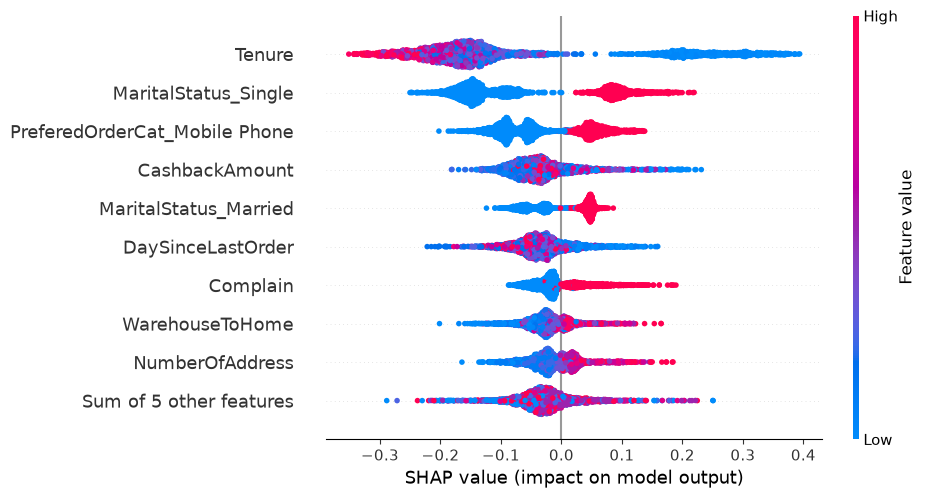

In [16]:
#safely extracting transformed data from X_test / bezpieczne wyciąganie przetransformowanych danych z X_test
if 'preprocessor' in best_pipeline.named_steps:
    preprocessor = best_pipeline.named_steps['preprocessor']
    X_train_transformed = preprocessor.transform(X_train)
    feature_names = preprocessor.get_feature_names_out()
else:
    X_train_transformed = X_train
    feature_names = X_train.columns

#converting to df for plot readability / konwersja do ramki danych dla czytelności wykresu
X_train_df = pd.DataFrame(X_train_transformed, columns=feature_names)

#calculating SHAP values / obliczanie wartości SHAP
explainer = shap.TreeExplainer(rf_model)
shap_values = explainer(X_train_df)

#values for Churn = 1 / wartości dla Churn = 1
if len(shap_values.shape) == 3:
    shap_values_churn = shap_values[:, :, 1]
else:
    shap_values_churn = shap_values

#Beeswarm
plt.figure(figsize=(10, 6))
shap.plots.beeswarm(shap_values_churn, max_display=10)

### ENG

> The beeswarm plot above illustrates the global explainability of the optimized Random Forest model. It combines feature importance information with the direction of their impact on churn prediction (class 1).

---

> **Key features and their direction of impact**
>
> **`Tenure`**
> * High values (red color) cluster on the left side (negative SHAP values), meaning that a **long customer tenure strongly protects against leaving**.
> * Low tenure values (blue color) are shifted to the right, confirming that **new clients are the most susceptible to churn**.
>
> **`MaritalStatus_Single` and `PreferedOrderCat_Mobile Phone`:**
> * High values (red points) for being single and preferring mobile phone orders generate positive SHAP values, which **increases the risk of churn**.
>
> **`CashbackAmount`:**
> * The varied distribution of points shows that moderate and higher cashback amounts help retain customers (shifted to the left).
>
> **`Complain`:**
> * In line with earlier models, the presence of complaints strongly shifts values toward the positive side (right side of the plot), which drastically **increases the probability of leaving**.

---

> **Conclusions and recommendations**
>
> **Risk window for new customers**
> * The main conclusion from the SHAP analysis is that key retention efforts should be focused at the beginning of the customer life cycle (low `Tenure`), before they manage to build loyalty toward the platform.
>
> **Experience personalization**
> * Mobile shoppers and single customers represent a higher-risk segment for whom dedicated, more engaging campaigns should be prepared.

### PL

>Powyższy wykres *beeswarm* przedstawia globalną wyjaśnialność zoptymalizowanego modelu Random Forest. Łączy on informację o ważności cech z kierunkiem ich wpływu na predykcję churnu (klasy 1).

---

>**Kluczowe cechy i ich kierunek wpływu**
>
>**`Tenure` (Staż)** 
>
>  * Wysokie wartości (kolor czerwony) skupiają się po lewej stronie (ujemne wartości SHAP), co oznacza, że **duży staż klienta silnie chroni przed odejściem**. 
>  * Niskie wartości stażu (kolor niebieski) przesunięte są w prawo, co potwierdza, że **nowi klienci są najbardziej podatni na rezygnację**.
>    
>**`MaritalStatus_Single` (Status singla) oraz PreferedOrderCat_Mobile Phone:**
>
>  * Wysokie wartości (czerwone punkty) dla bycia singlem oraz preferowania zamówień przez telefon generują dodatnie wartości SHAP, co **zwiększa ryzyko churnu**.
>    
>**`CashbackAmount` (Wysokość cashbacku):**
>  * Zróżnicowany rozkład punktów pokazuje, że umiarkowane i wyższe kwoty cashbacku pomagają zatrzymać klientów (przesunięcie w lewo).
>    
> **`Complain` (Skargi):**
>  * Zgodnie z wcześniejszymi modelami, obecność skarg mocno przesuwa wartości w stronę dodatnią (prawa strona wykresu), co drastycznie **podnosi prawdopodobieństwo rezygnacji**.

---

>**Wnioski i rekomendacje**
>
>**Okno ryzyka dla nowych klientów**
>
>* Głównym wnioskiem z analizy SHAP jest to, że kluczowe działania retencyjne powinny być skoncentrowane na początku cyklu życia klienta (niski `Tenure`), zanim zdąży on zbudować lojalność wobec platformy.
>
>**Personalizacja doświadczeń**
>
>* Klienci mobilni oraz single stanowią segment podwyższonego ryzyka, dla którego warto przygotować dedykowane, bardziej atrakcyjne kampanie angażujące.

## 6. Business deployment & export

In [16]:
#calculating churn probabilities for the test set (X_test) / obliczanie prawdopodobieństwa odejścia dla bazy testowej (X_test)
X_test_proba = grid_search.best_estimator_.predict_proba(X_test)[:, 1]

#creating a results DataFrame with a 35% business threshold / tworzenie ramki z wynikami i progiem biznesowym = 35%
THRESHOLD = 0.35
results_df = X_test.copy()
results_df['churn_probability'] = X_test_proba
results_df['target_campaign'] = (results_df['churn_probability'] >= THRESHOLD).astype(int)

#extracting at-risk customers and sorting them by highest risk / wyciągnięcie klientów zagrożonych i posortowanie po najwyższym ryzyku
priority_list = results_df[results_df['target_campaign'] == 1].sort_values(
    by='churn_probability', 
    ascending=False
)

In [17]:
priority_list.to_csv('churn_risk_clients.csv', index=False)

print(f"✅ File 'churn_risk_clients.csv' generated successfully.")
print(f"Number of selected customers targeted for the retention campaign: {len(priority_list)}")

✅ File 'churn_risk_clients.csv' generated successfully.
Number of selected customers targeted for the retention campaign: 165


In [17]:
joblib.dump(best_pipeline, 'churn_random_forest_model.pkl')

['churn_random_forest_model.pkl']

## 7. Summary

### ENG

> **Methodology and data preparation**
>
> To eliminate the risk of data leakage, the project integrated data processing pipelines and stratified cross-validation (`StratifiedKFold`).

> **Model selection**
>
> Among the tested algorithms (Logistic Regression, XGBoost, Random Forest), the Random Forest model achieved the best balance of metrics, including the highest ROC-AUC ($0.9282$) and F1-Score ($0.6962$).

> **Results after hyperparameter tuning**
>
> The application of `GridSearchCV` allowed for optimizing model parameters (e.g., `n_estimators=200`, `criterion='entropy'`), which raised the overall F1-Score to $0.71$. The Recall metric increased to $0.73$ (correctly identifying 323 out of 442 churning customers), and Precision reached $0.68$ while simultaneously reducing false alarms (the number of False Positives dropped to 150).

> **Interpretability and business implementation**
>
> Thanks to explainable artificial intelligence (XAI) tools, feature importance analysis, and SHAP, the main churn risk factors were identified, such as customer tenure (`Tenure`) and filed complaints (`Complain`). The final result of the project is the generation of a database of at-risk customers (`churn_risk_clients.csv`), which provides the marketing department with ready-to-use data for the immediate launch of targeted retention campaigns.

### PL

>**Metodologia i przygotowanie danych**
>
>W celu eliminacji ryzyka przecieku danych, w projekcie zintegrowano potoki przetwarzania danych (pipeline) oraz stratyfikowaną walidację krzyżową (`StratifiedKFold`).

>**Wybór modelu**
>
>Spośród testowanych algorytmów (regresja logistyczna, XGBoost, Random Forest), model Random Forest osiągnął najlepszy balans metryk, w tym najwyższy ROC-AUC ($0.9282$) oraz F1-Score ($0.6962$).

>**Wyniki po tuningu hiperparametrów**
>
>Zastosowanie `GridSearchCV` pozwoliło zoptymalizować parametry modelu (m.in. `n_estimators=200`, `criterion='entropy'`), co podniosło ogólny F1-Score do poziomu $0.71$. Wskaźnik Recall wzrosnął do $0.73$ (poprawnie zidentyfikowano 323 z 442 odchodzących klientów), a Precision osiągnęła $0.68$ przy jednoczesnym ograniczeniu fałszywych alarmów (liczba False Positives spadła do 150).

>**Interpretowalność i wdrażanie biznesowe**
>
>Dzięki narzędziom wyjaśnialnej sztucznej inteligencji (XAI, analiza ważności cech oraz SHAP) zidentyfikowano główne czynniki ryzyka rezygnacji, takie jak staż klienta (`Tenure`) oraz zgłaszane reklamacje (`Complain`). Ostatecznym rezultatem projektu jest wygenerowanie bazy zagrożonych klientów (`churn_risk_clients.csv`), która dostarcza działowi marketingu gotowych danych do natychmiastowego uruchomienia celowanych kampanii retencyjnych.  